# Week 6 — Seoul Bike: API Integration and Future Demand Forecast

**Team B · Data integration → model calibration → historical evaluation → future hourly forecasts**

This notebook extends our **Week 5 linear one-hour-ahead model**, not the Week 3 multiplicative model or Week 4 synchronization.

- **Original model:** `D(t+1) = b0 + b1 D(t) + b2 T(t+1) + b3 H(t+1) + hour_effect`
- **Extended model:** same equation **plus** `b4 CloudCover(t+1)`.
- **Historical mode:** retrieve cloud cover from the Open-Meteo Historical Weather API, integrate with Seoul rentals, fit both versions on identical training rows, evaluate on later observations.
- **Future mode:** retrieve *forecast* temperature, humidity and cloud cover from the Open-Meteo Forecast API; predict future rentals recursively using **fixed coefficients**.

**Limitations:** Seoul rental observations are from **2017–2018**, not today. Without a live rental feed, future estimates use an explicitly labelled *historical-profile seed* (or a manually entered seed), not the latest real rental count. This is a **scenario forecast**, not a validated live digital twin. Historical reanalysis values are retrospectively available; historical evaluation assumes next-hour weather is perfectly forecast. Predictions of future rentals cannot be scored until real future observations exist.

**External data:** Open-Meteo (`https://open-meteo.com/`); location **37.57 N, 126.96 E**, timezone `Asia/Seoul`. Historical API cache fallback uses the provided CSV in UTC, explicitly converted to Seoul local time.

## 1 — Imports and configuration

Place `SeoulBikeData.csv` in the repository root, and optionally put the downloaded historical Open-Meteo CSV in `Week-6/`. **Historical weather is fetched via API first**; if the API is unreachable, the CSV can be used as a disclosed backup. The **live forecast never uses the historical CSV**.

In [1]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

BIKE_FILE = "SeoulBikeData.csv"
HISTORICAL_BACKUP = "open-meteo-37.57N126.96E27m.csv"
LAT, LON = 37.57, 126.96
TIMEZONE = "Asia/Seoul"
HISTORICAL_API = "https://archive-api.open-meteo.com/v1/archive"
FORECAST_API = "https://api.open-meteo.com/v1/forecast"
FORECAST_DAYS = 3
PREDICTION_HOURS = 24

# "historical_profile": typical rental count for the hour before the first forecast hour.
# "manual": explicitly supplied hypothetical or externally observed initial rental count.
SEED_MODE = "historical_profile"
MANUAL_SEED_RENTALS = 500.0

# Keep API responses reproducible after initial retrieval.
CACHE_DIR = Path(".week6_cache")
CACHE_DIR.mkdir(exist_ok=True)


def find_file(filename):
    for path in [Path(filename), Path("..") / filename, Path("Week-6") / filename]:
        if path.exists():
            return path
    raise FileNotFoundError(f"Cannot find {filename}")


def request_json(url, params):
    response = requests.get(url, params=params, timeout=40)
    response.raise_for_status()
    payload = response.json()
    if payload.get("error"):
        raise ValueError(payload.get("reason", "Open-Meteo API error"))
    if "hourly" not in payload:
        raise ValueError("Open-Meteo response is missing the 'hourly' field")
    return payload

bike_path = find_file(BIKE_FILE)
print("Bike file:", bike_path)
print("Historical API:", HISTORICAL_API)
print("Forecast API:", FORECAST_API)

Bike file: ..\SeoulBikeData.csv
Historical API: https://archive-api.open-meteo.com/v1/archive
Forecast API: https://api.open-meteo.com/v1/forecast


## 2 — Load and validate Seoul rental observations

Seoul's original dataset uses local dates and integer hours. We make timestamps timezone-aware and preserve only valid observations. The bike dataset is the only source of **observed rental counts**.

In [2]:
bike = pd.read_csv(bike_path, encoding="latin1")
required = ["Date", "Hour", "Rented Bike Count", "Temperature(°C)",
            "Humidity(%)", "Functioning Day"]
missing_columns = sorted(set(required) - set(bike.columns))
if missing_columns:
    raise ValueError(f"Missing bike columns: {missing_columns}")

bike["Timestamp"] = (
    pd.to_datetime(bike["Date"], dayfirst=True)
    + pd.to_timedelta(bike["Hour"], unit="h")
).dt.tz_localize(TIMEZONE)
print("Raw bike rows:", len(bike))
print("Missing required cells:", int(bike[required].isna().sum().sum()))
print("Duplicate timestamps:", int(bike["Timestamp"].duplicated().sum()))

bike = bike.dropna(subset=required + ["Timestamp"]).copy()
bike = bike.loc[
    (bike["Rented Bike Count"] >= 0)
    & bike["Humidity(%)"].between(0, 100)
    & bike["Hour"].between(0, 23)
    & bike["Functioning Day"].isin(["Yes", "No"])
].sort_values("Timestamp").reset_index(drop=True)
if bike["Timestamp"].duplicated().any():
    raise ValueError("Duplicate bike timestamps; resolve them before joining")
print("Valid bike rows:", len(bike))
print("Period:", bike.Timestamp.min(), "to", bike.Timestamp.max())

Raw bike rows: 8760
Missing required cells: 0
Duplicate timestamps: 0
Valid bike rows: 8760
Period: 2017-12-01 00:00:00+09:00 to 2018-11-30 23:00:00+09:00


## 3 — Load historical cloud cover from Open-Meteo API

The Historical API returns hourly cloud cover in **Seoul local time** because we set `timezone=Asia/Seoul`. API responses are saved to a local JSON cache for reproducibility. If there is a network/API failure, we try the supplied CSV backup, whose GMT timestamps are converted to Seoul time. We never silently hide the source used.

In [3]:
def historical_from_api(start_date, end_date):
    cache_file = CACHE_DIR / f"historical_cloud_{start_date}_{end_date}.json"
    params = {
        "latitude": LAT, "longitude": LON,
        "start_date": start_date, "end_date": end_date,
        "hourly": "cloud_cover", "timezone": TIMEZONE,
        "models": "era5"
    }
    try:
        payload = request_json(HISTORICAL_API, params)
        cache_file.write_text(json.dumps(payload), encoding="utf-8")
        source = "Open-Meteo Historical API (fresh download)"
    except (requests.RequestException, ValueError) as error:
        if not cache_file.exists():
            raise RuntimeError(f"Historical API unavailable and no JSON cache: {error}") from error
        payload = json.loads(cache_file.read_text(encoding="utf-8"))
        source = "Open-Meteo Historical API (saved JSON cache)"
        print("Historical API unavailable; using cached response:", error)

    hourly = payload["hourly"]
    result = pd.DataFrame({
        "Timestamp": pd.to_datetime(hourly["time"]).tz_localize(TIMEZONE),
        "cloud_cover_pct": pd.to_numeric(hourly["cloud_cover"], errors="coerce")
    })
    return result, source


def historical_from_csv():
    path = find_file(HISTORICAL_BACKUP)
    raw = pd.read_csv(path, skiprows=3)
    if not {"time", "cloud_cover (%)"}.issubset(raw.columns):
        raise ValueError("Unexpected CSV columns; expected time and cloud_cover (%)")
    result = pd.DataFrame({
        "Timestamp": pd.to_datetime(raw["time"], utc=True).dt.tz_convert(TIMEZONE),
        "cloud_cover_pct": pd.to_numeric(raw["cloud_cover (%)"], errors="coerce")
    })
    return result, f"Open-Meteo Historical Weather CSV backup ({path})"

start_date = bike.Timestamp.min().date().isoformat()
end_date = bike.Timestamp.max().date().isoformat()
try:
    cloud, cloud_source = historical_from_api(start_date, end_date)
except RuntimeError as error:
    print("API/cache unavailable:", error)
    cloud, cloud_source = historical_from_csv()

cloud = cloud.sort_values("Timestamp").reset_index(drop=True)
if cloud["Timestamp"].isna().any() or cloud["Timestamp"].duplicated().any():
    raise ValueError("Invalid or duplicate historical weather timestamps")
if (cloud["cloud_cover_pct"].dropna().between(0, 100) == False).any():
    raise ValueError("Historical cloud cover outside 0-100%")
print("Historical weather source:", cloud_source)
print("Historical weather rows:", len(cloud))
print("Cloud period:", cloud.Timestamp.min(), "to", cloud.Timestamp.max())

Historical weather source: Open-Meteo Historical API (fresh download)
Historical weather rows: 8760
Cloud period: 2017-12-01 00:00:00+09:00 to 2018-11-30 23:00:00+09:00


## 4 — Join sources and check data quality

The timestamps must refer to the *same local hour*. A left join retains all rental rows; missing external measurements are reported explicitly. Later, both model variants use exactly the same available examples.

In [4]:
integrated = bike.merge(
    cloud[["Timestamp", "cloud_cover_pct"]],
    on="Timestamp", how="left", validate="one_to_one"
)
cloud_matches = integrated["cloud_cover_pct"].notna().sum()
missing_cloud = int(integrated["cloud_cover_pct"].isna().sum())
missing_hours = int((integrated["Timestamp"].diff().dropna() != pd.Timedelta(hours=1)).sum())
print(f"Cloud matches: {cloud_matches}/{len(integrated)} ({cloud_matches/len(integrated):.2%})")
print("Missing cloud values:", missing_cloud)
print("Nonconsecutive timestamp gaps:", missing_hours)
if cloud_matches == 0:
    raise ValueError("No cloud timestamps matched. Check timezone conversion.")
print(integrated[["Timestamp", "Rented Bike Count", "Temperature(°C)",
                  "Humidity(%)", "cloud_cover_pct"]].head().to_string(index=False))

Cloud matches: 8760/8760 (100.00%)
Missing cloud values: 0
Nonconsecutive timestamp gaps: 0
                Timestamp  Rented Bike Count  Temperature(°C)  Humidity(%)  cloud_cover_pct
2017-12-01 00:00:00+09:00                254             -5.2           37               10
2017-12-01 01:00:00+09:00                204             -5.5           38                3
2017-12-01 02:00:00+09:00                173             -6.0           39                2
2017-12-01 03:00:00+09:00                107             -6.2           40                2
2017-12-01 04:00:00+09:00                 78             -6.0           36                0


## 5 — Create one-hour-ahead examples with **no target leakage**

For forecast issued at hour `t`, predictors are: observed rentals `D(t)`, known/forecast `T(t+1)`, `H(t+1)`, `Cloud(t+1)`, and calendar hour `h(t+1)`. Target `D(t+1)` is used **only to train/evaluate**. In retrospective evaluation we assume the recorded next-hour weather had been available at issue time (*perfect-weather-forecast assumption*). Consecutive operating hours only.

In [5]:
now = integrated.iloc[:-1].reset_index(drop=True)
nxt = integrated.iloc[1:].reset_index(drop=True)
pairs = pd.DataFrame({
    "Timestamp": nxt["Timestamp"],
    "D_current": now["Rented Bike Count"].astype(float),
    "T_next": nxt["Temperature(°C)"].astype(float),
    "H_next": nxt["Humidity(%)"].astype(float),
    "Cloud_next": nxt["cloud_cover_pct"].astype(float),
    "Hour_next": nxt["Timestamp"].dt.hour.astype(int),
    "D_next": nxt["Rented Bike Count"].astype(float)
})
consecutive = nxt["Timestamp"].sub(now["Timestamp"]).eq(pd.Timedelta(hours=1))
operating = now["Functioning Day"].eq("Yes") & nxt["Functioning Day"].eq("Yes")
valid = consecutive & operating & pairs["Cloud_next"].notna()
pairs = pairs.loc[valid].reset_index(drop=True)
if len(pairs) < 100:
    raise ValueError("Too few valid prediction pairs")

n = len(pairs)
train = pairs.iloc[:int(0.70 * n)].copy()
tune = pairs.iloc[int(0.70 * n):int(0.85 * n)].copy()
test = pairs.iloc[int(0.85 * n):].copy()
assert train.Timestamp.max() < tune.Timestamp.min() < test.Timestamp.min()
for name, part in [("Train", train), ("Tune", tune), ("Test", test)]:
    print(name, len(part), part.Timestamp.min(), "->", part.Timestamp.max())

Train 5916 2017-12-01 01:00:00+09:00 -> 2018-08-06 14:00:00+09:00
Tune 1268 2018-08-06 15:00:00+09:00 -> 2018-10-03 14:00:00+09:00
Test 1268 2018-10-03 15:00:00+09:00 -> 2018-11-30 23:00:00+09:00


## 6 — Define both Week 5 / Week 6 equations

The only input difference is `Cloud_next` (coefficient `b4`). `Hour_1` to `Hour_23` represent time-of-day corrections; hour 0 is the reference hour. **No observed next-hour rental count is in the feature matrix.**

In [6]:
FEATURES_BASE = ["b0", "b1_D_current", "b2_temperature", "b3_humidity"] + [f"hour_{h}" for h in range(1,24)]
FEATURES_CLOUD = FEATURES_BASE[:4] + ["b4_cloud_cover"] + FEATURES_BASE[4:]


def design_matrix(data, include_cloud=False):
    hour = data["Hour_next"].to_numpy(dtype=int)
    columns = [
        np.ones(len(data)),
        data["D_current"].to_numpy(dtype=float),
        data["T_next"].to_numpy(dtype=float),
        data["H_next"].to_numpy(dtype=float),
    ]
    if include_cloud:
        columns.append(data["Cloud_next"].to_numpy(dtype=float))
    columns.extend((hour == h).astype(float) for h in range(1, 24))
    return np.column_stack(columns)


def predict(data, coefficients, include_cloud=False):
    # Negative demand is not meaningful; clip model output, do not round internally.
    return np.maximum(0.0, design_matrix(data, include_cloud) @ coefficients)

assert len(FEATURES_BASE) == 27 and len(FEATURES_CLOUD) == 28

## 7 — Calibrate on historical training data only

We train the original and extended models **independently on identical rows**, using ordinary least squares (`np.linalg.lstsq`). Coefficients are then frozen. The resulting cloud coefficient has units of rentals per hour per percentage point of cloud cover; its sign expresses association, not causality.

In [7]:
y_train = train["D_next"].to_numpy(dtype=float)
X_base = design_matrix(train, include_cloud=False)
X_cloud = design_matrix(train, include_cloud=True)
b_base, _, rank_base, _ = np.linalg.lstsq(X_base, y_train, rcond=None)
b_cloud, _, rank_cloud, _ = np.linalg.lstsq(X_cloud, y_train, rcond=None)
if rank_base < X_base.shape[1] or rank_cloud < X_cloud.shape[1]:
    raise ValueError("Feature matrix rank deficient: cannot fit all coefficients uniquely")

coefficients = pd.DataFrame({
    "Term": FEATURES_CLOUD[:5],
    "Original": [*b_base[:4], np.nan],
    "With cloud cover": b_cloud[:5]
})
print(coefficients.round(4).to_string(index=False))
print(f"Cloud coefficient b4: {b_cloud[4]:+.4f} rentals/hour per % point")

# Store trained parameters and feature names to reuse without refitting.
model_path = CACHE_DIR / "seoul_week6_coefficients.npz"
np.savez(model_path, base=b_base, cloud=b_cloud,
         features_base=np.array(FEATURES_BASE), features_cloud=np.array(FEATURES_CLOUD))
print("Saved trained coefficients:", model_path)

          Term  Original  With cloud cover
            b0  -21.3227          -20.3248
  b1_D_current    0.8692            0.8686
b2_temperature    4.3642            4.3975
   b3_humidity   -1.0406           -0.9771
b4_cloud_cover       NaN           -0.0940
Cloud coefficient b4: -0.0940 rentals/hour per % point
Saved trained coefficients: .week6_cache\seoul_week6_coefficients.npz


## 8 — Evaluate on held-out historical observations

Report **MAE**, **RMSE**, and a persistence benchmark (`D(t+1)=D(t)`). The models are evaluated on the same test hours; tune/test are never used for fitting. Historical evaluation is a one-step-ahead protocol, whereas the future multi-hour prediction below is recursive and therefore harder.

In [8]:
def mae(y, p):
    return float(np.mean(np.abs(np.asarray(y) - np.asarray(p))))


def rmse(y, p):
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))

metrics_rows = []
for split, part in [("Train", train), ("Tune", tune), ("Test", test)]:
    actual = part["D_next"].to_numpy(dtype=float)
    methods = {
        "Week 5 (no cloud)": predict(part, b_base, False),
        "Week 6 (+ cloud)": predict(part, b_cloud, True),
        "Persistence": part["D_current"].to_numpy(dtype=float),
    }
    for name, forecast in methods.items():
        metrics_rows.append({"Split": split, "Model": name, "Hours": len(part),
                             "MAE": mae(actual, forecast), "RMSE": rmse(actual, forecast)})
metrics = pd.DataFrame(metrics_rows)
print(metrics.round(2).to_string(index=False))
base_test_mae = float(metrics.query("Split == 'Test' and Model == 'Week 5 (no cloud)'")["MAE"].iloc[0])
cloud_test_mae = float(metrics.query("Split == 'Test' and Model == 'Week 6 (+ cloud)'")["MAE"].iloc[0])
print(f"Test MAE change: {base_test_mae-cloud_test_mae:+.2f} rentals/hour (positive = improvement)")
print(f"Relative change: {100*(base_test_mae-cloud_test_mae)/base_test_mae:+.2f}%")

test_results = test[["Timestamp", "D_next"]].rename(columns={"D_next": "Observed"}).copy()
test_results["Week 5"] = predict(test, b_base, False)
test_results["Week 6 + cloud"] = predict(test, b_cloud, True)

Split             Model  Hours    MAE   RMSE
Train Week 5 (no cloud)   5916 125.97 188.57
Train  Week 6 (+ cloud)   5916 126.02 188.55
Train       Persistence   5916 163.76 265.33
 Tune Week 5 (no cloud)   1268 162.57 225.07
 Tune  Week 6 (+ cloud)   1268 162.58 224.96
 Tune       Persistence   1268 238.96 337.24
 Test Week 5 (no cloud)   1268 131.43 194.81
 Test  Week 6 (+ cloud)   1268 131.14 194.62
 Test       Persistence   1268 214.89 313.91
Test MAE change: +0.30 rentals/hour (positive = improvement)
Relative change: +0.23%


## 9 — Historical comparison plot

An hourly time index prevents lines from connecting across missing/closed hours.

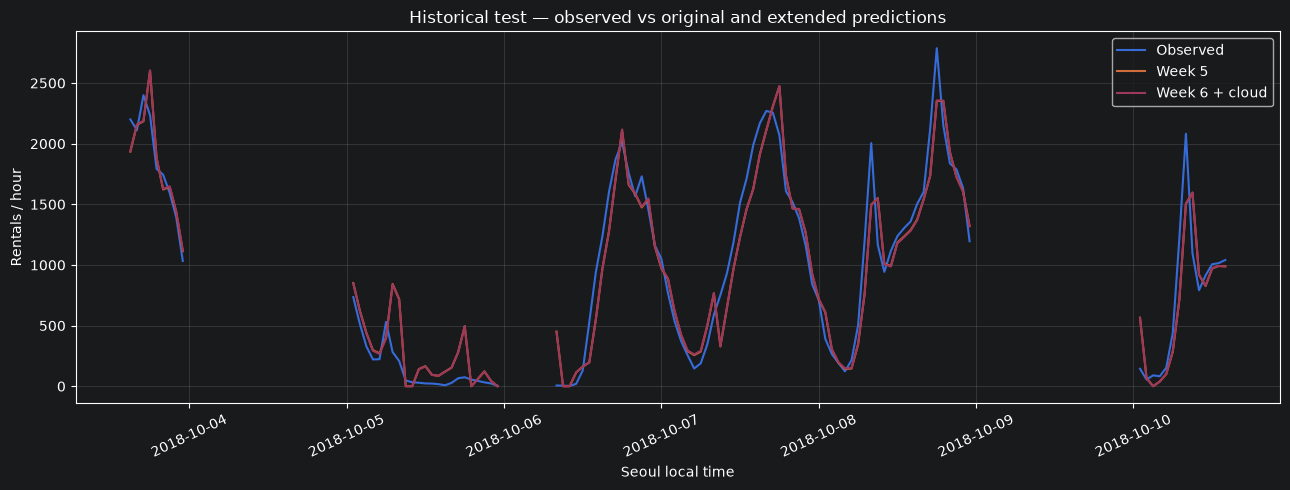

In [9]:
first = test_results.Timestamp.min()
week = test_results[test_results.Timestamp < first + pd.Timedelta(days=7)]
week = week.set_index("Timestamp").asfreq("h")
plt.figure(figsize=(13, 5))
for series in ["Observed", "Week 5", "Week 6 + cloud"]:
    plt.plot(week.index, week[series], label=series)
plt.title("Historical test — observed vs original and extended predictions")
plt.xlabel("Seoul local time")
plt.ylabel("Rentals / hour")
plt.xticks(rotation=25)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

## 10 — Live future weather via Open-Meteo **Forecast API**

This is a **different endpoint** from historical weather. It requests forecast `temperature_2m`, `relative_humidity_2m`, and `cloud_cover`. The server returns **Seoul local times**. We retain only future hours strictly after the current Seoul local hour, remove rows with missing weather, and verify hourly continuity. A failed request is not treated as a successful live forecast.

In [10]:
def fetch_future_weather():
    params = {
        "latitude": LAT, "longitude": LON,
        "hourly": "temperature_2m,relative_humidity_2m,cloud_cover",
        "timezone": TIMEZONE,
        "forecast_days": FORECAST_DAYS,
    }
    payload = request_json(FORECAST_API, params)
    hourly = payload["hourly"]
    forecast = pd.DataFrame({
        "Timestamp": pd.to_datetime(hourly["time"]).tz_localize(TIMEZONE),
        "T_next": pd.to_numeric(hourly["temperature_2m"], errors="coerce"),
        "H_next": pd.to_numeric(hourly["relative_humidity_2m"], errors="coerce"),
        "Cloud_next": pd.to_numeric(hourly["cloud_cover"], errors="coerce"),
    }).sort_values("Timestamp").reset_index(drop=True)
    if forecast.Timestamp.duplicated().any():
        raise ValueError("Duplicate forecast timestamps")
    current_hour = pd.Timestamp.now(tz=TIMEZONE).floor("h")
    forecast = forecast[forecast.Timestamp > current_hour].copy()
    forecast = forecast.dropna(subset=["T_next", "H_next", "Cloud_next"])
    if not forecast.H_next.between(0,100).all() or not forecast.Cloud_next.between(0,100).all():
        raise ValueError("Invalid forecast humidity/cloud cover")
    forecast["Hour_next"] = forecast.Timestamp.dt.hour
    forecast = forecast.head(PREDICTION_HOURS).reset_index(drop=True)
    if forecast.empty:
        raise ValueError("No future weather hours available")
    if not forecast.Timestamp.diff().dropna().eq(pd.Timedelta(hours=1)).all():
        raise ValueError("Forecast contains missing hours; do not recurse across gaps")
    return forecast

try:
    future_weather = fetch_future_weather()
    print("LIVE weather forecast downloaded:", len(future_weather), "hours")
    print(future_weather.head().to_string(index=False))
except (requests.RequestException, RuntimeError, KeyError, ValueError) as error:
    future_weather = pd.DataFrame()
    print("LIVE FORECAST UNAVAILABLE:", error)
    print("No future rental graph will be generated without a real Forecast API response.")

LIVE weather forecast downloaded: 24 hours
                Timestamp  T_next  H_next  Cloud_next  Hour_next
2026-11-13 02:00:00+09:00     8.7      97          69          2
2026-11-13 03:00:00+09:00     8.5      98          78          3
2026-11-13 04:00:00+09:00     8.4      98          75          4
2026-11-13 05:00:00+09:00     8.3      98          67          5
2026-11-13 06:00:00+09:00     8.2      99          72          6


## 11 — Select a transparent initial rental demand

The linear model requires observed `D(t)` to predict `D(t+1)`.

- `SEED_MODE = "manual"`: use `MANUAL_SEED_RENTALS` as an explicitly provided/assumed rental count for the hour preceding the first forecast.
- `SEED_MODE = "historical_profile"` (default): use the **median observed rentals for that hour of day from the *training period***. This is a historical scenario assumption, **not** a current measurement.

The seed is recorded in the outputs. Without live rental data we must **not** claim these are accurate present-day forecasts.

In [11]:
def initial_demand(forecast):
    previous_hour = forecast.Timestamp.iloc[0] - pd.Timedelta(hours=1)
    if SEED_MODE == "manual":
        if MANUAL_SEED_RENTALS < 0:
            raise ValueError("MANUAL_SEED_RENTALS must be nonnegative")
        return float(MANUAL_SEED_RENTALS), "Manual/assumed initial rental count"
    if SEED_MODE == "historical_profile":
        matching = train.loc[train["Timestamp"].dt.hour == previous_hour.hour, "D_next"]
        if matching.empty:
            raise ValueError("No historical training observations for seed hour")
        return float(matching.median()), "Historical training median at previous hour (not live)"
    raise ValueError("SEED_MODE must be 'manual' or 'historical_profile'")

if not future_weather.empty:
    seed_value, seed_source = initial_demand(future_weather)
    print(f"Initial rental demand: {seed_value:.1f}; source: {seed_source}")

Initial rental demand: 278.0; source: Historical training median at previous hour (not live)


## 12 — Recursive future rental prediction

At first forecast hour, the model uses the seed `D(t)`. For the second and later future hours, it uses the **previous predicted rental count** instead of future unknown observations. Forecast weather is supplied by the API. All model coefficients are **frozen**. We run both the Week 5 and Week 6 models with the same seed and weather timestamps.

In [12]:
def recursive_forecast(weather_forecast, coefficients, include_cloud, seed):
    last_demand = float(seed)
    results = []
    for row in weather_forecast.itertuples(index=False):
        one_hour = pd.DataFrame([{
            "D_current": last_demand,
            "T_next": row.T_next,
            "H_next": row.H_next,
            "Cloud_next": row.Cloud_next,
            "Hour_next": row.Hour_next,
        }])
        estimated = float(predict(one_hour, coefficients, include_cloud)[0])
        results.append(estimated)
        last_demand = estimated
    return np.asarray(results)

if not future_weather.empty:
    future_results = future_weather.copy()
    future_results["Week 5 forecast"] = recursive_forecast(future_weather, b_base, False, seed_value)
    future_results["Week 6 + cloud forecast"] = recursive_forecast(future_weather, b_cloud, True, seed_value)
    future_results["Seed rentals"] = seed_value
    future_results["Seed source"] = seed_source
    future_results["Observation status"] = "FORECAST — no observed rental count"
    print(future_results.head(12).to_string(index=False))
else:
    future_results = pd.DataFrame()
    print("Future rental predictions skipped: no live weather forecast.")

                Timestamp  T_next  H_next  Cloud_next  Hour_next  Week 5 forecast  Week 6 + cloud forecast  Seed rentals                                            Seed source                  Observation status
2026-11-13 02:00:00+09:00     8.7      97          69          2       151.958137               152.540673         278.0 Historical training median at previous hour (not live) FORECAST — no observed rental count
2026-11-13 03:00:00+09:00     8.5      98          78          3        44.986545                45.444126         278.0 Historical training median at previous hour (not live) FORECAST — no observed rental count
2026-11-13 04:00:00+09:00     8.4      98          75          4         0.000000                 0.000000         278.0 Historical training median at previous hour (not live) FORECAST — no observed rental count
2026-11-13 05:00:00+09:00     8.3      98          67          5         0.000000                 0.000000         278.0 Historical training median at p

## 13 — Future prediction graph

These are **predictions**, not measured bike rental counts. No future MAE or RMSE can be computed. Recursive uncertainty generally increases with the forecast horizon.

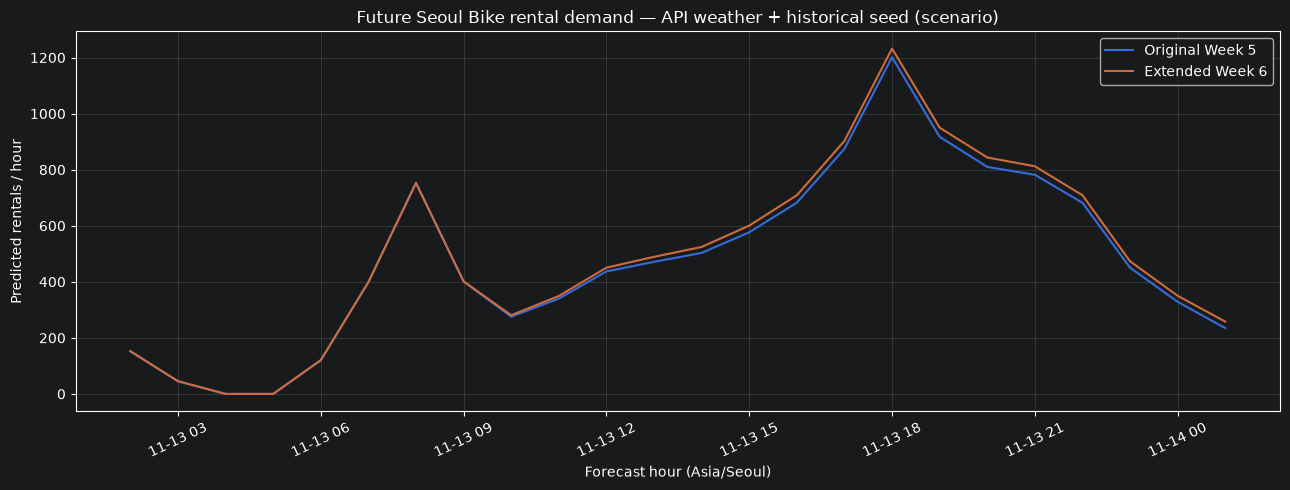

In [13]:
if not future_results.empty:
    plt.figure(figsize=(13, 5))
    plt.plot(future_results.Timestamp, future_results["Week 5 forecast"], label="Original Week 5")
    plt.plot(future_results.Timestamp, future_results["Week 6 + cloud forecast"], label="Extended Week 6")
    plt.title("Future Seoul Bike rental demand — API weather + historical seed (scenario)")
    plt.xlabel("Forecast hour (Asia/Seoul)")
    plt.ylabel("Predicted rentals / hour")
    plt.xticks(rotation=25)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No graph: a live Open-Meteo Forecast API response is required.")

## 14 — Save outputs and document provenance

The historical evaluation is supported by observed 2017–2018 rentals. The future graph depends on the live API's issue-time forecasts and an assumed historical seed. We save separate datasets so nobody confuses observed rentals with predicted future demand. The Weather API and model information should be cited in the presentation.

In [14]:
OUTPUT_DIR = Path("week6_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
metrics.to_csv(OUTPUT_DIR / "historical_metrics.csv", index=False)
test_results.to_csv(OUTPUT_DIR / "historical_test_predictions.csv", index=False)
if not future_results.empty:
    future_results.to_csv(OUTPUT_DIR / "future_api_forecast.csv", index=False)
metadata = {
    "historical_weather_source": cloud_source,
    "historical_mode": "Retrospective perfect next-hour weather assumption",
    "future_weather_source": "Open-Meteo Forecast API" if not future_results.empty else "unavailable",
    "future_prediction_is_observation": False,
    "seed_mode": SEED_MODE,
    "seed_source": seed_source if not future_results.empty else None,
    "forecast_hours": int(len(future_results)),
    "model_family": "Week 5 linear model, Week 6 adds cloud_cover_pct",
    "historical_test_mae_base": base_test_mae,
    "historical_test_mae_cloud": cloud_test_mae,
}
(OUTPUT_DIR / "provenance.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Outputs:", OUTPUT_DIR.resolve())
print("Historical Test MAE: original", round(base_test_mae, 2),
      "| extended", round(cloud_test_mae, 2))
print("Future forecast status:", "generated from live API" if not future_results.empty else "not available")

Outputs: C:\Users\hazid\Documents\Digital Twins\Project-Mappa\Week-6\week6_outputs
Historical Test MAE: original 131.43 | extended 131.14
Future forecast status: generated from live API
